Found model '2D_versatile_fluo' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.479071, nms_thresh=0.3.


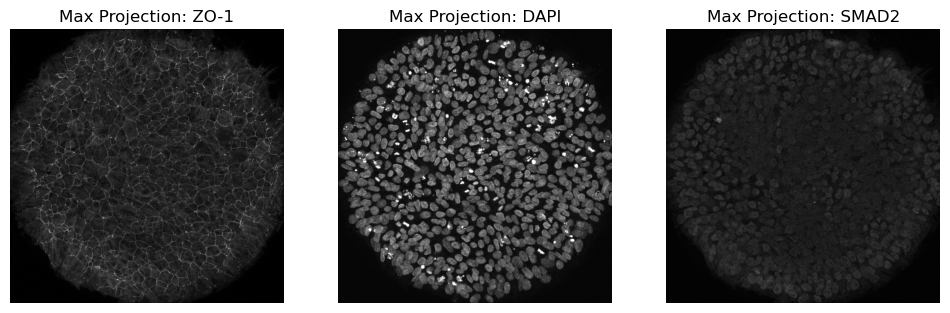

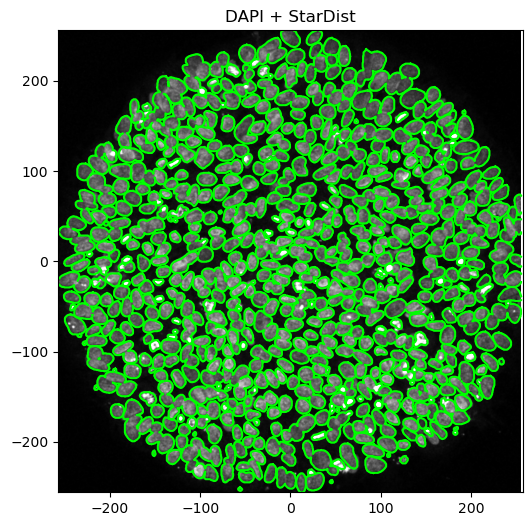

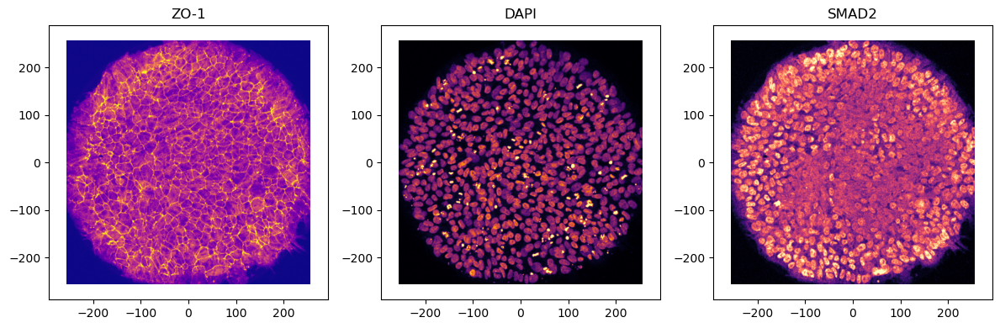

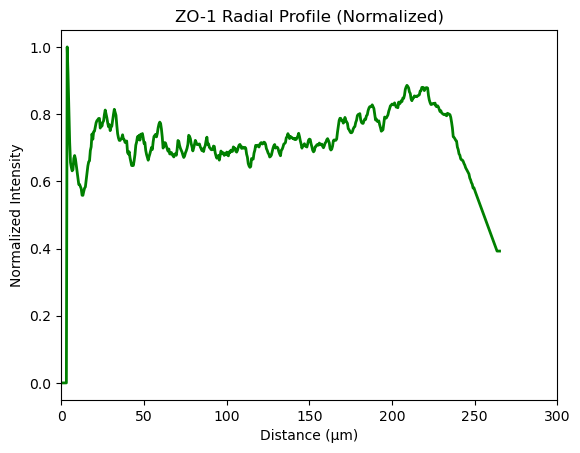

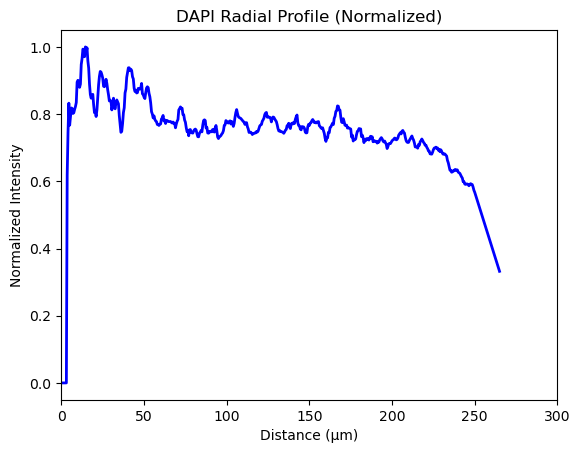

...

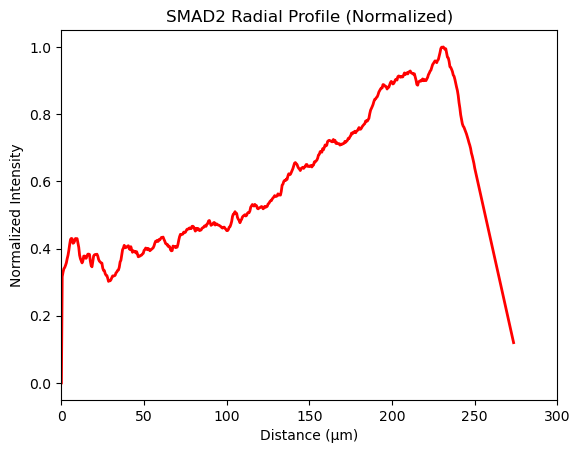

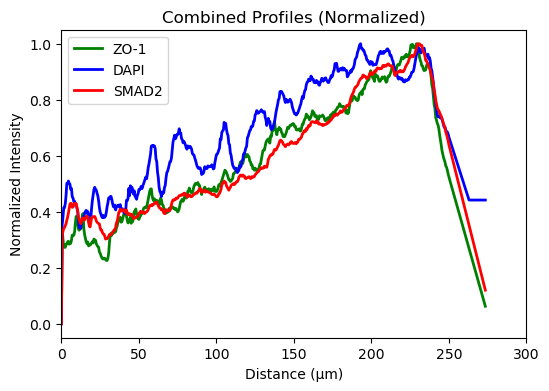

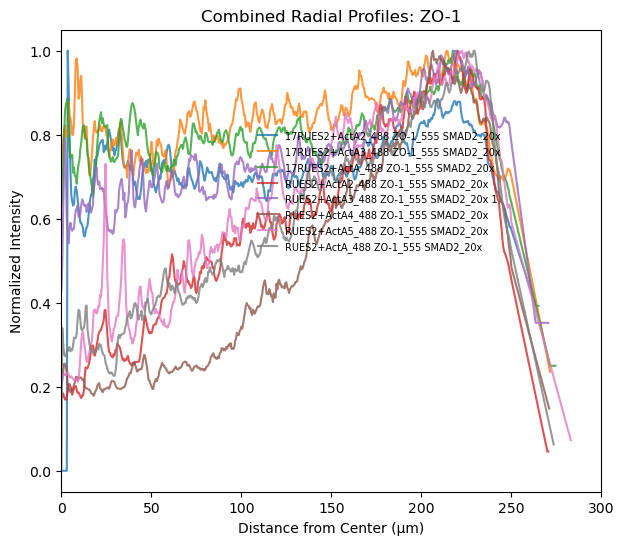

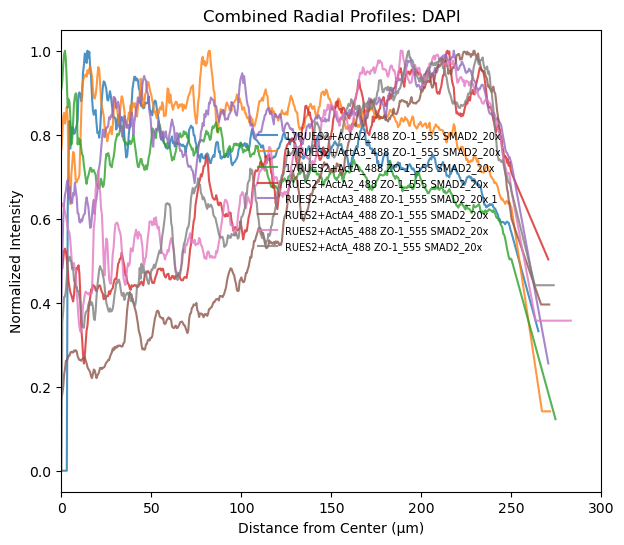

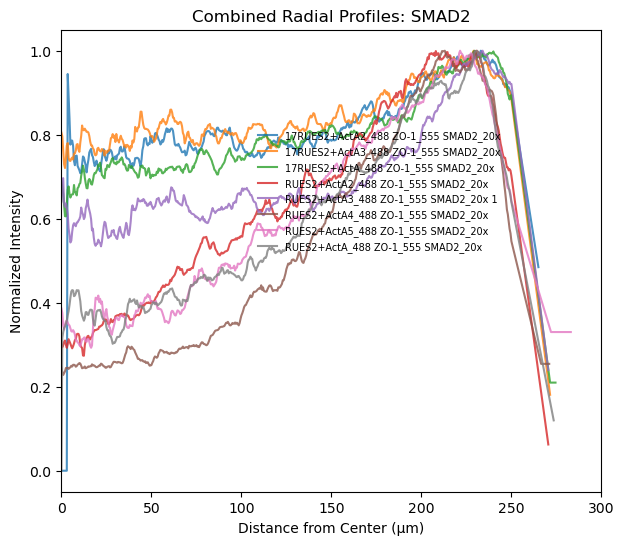

PowerPoint saved at PATH_TO_YOUR_TIFF_FOLDER/ppt_reports/batch_report.pptx


In [1]:
# To install dependencies, run:
# pip install numpy pandas matplotlib tifffile scipy scikit-image csbdeep stardist python-pptx
# pip install git+https://github.com/broadinstitute/tapenade.git

import os
import re
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, center_of_mass
from skimage.measure import find_contours
from stardist.models import StarDist2D
from csbdeep.utils import normalize
from tapenade.preprocessing import global_contrast_enhancement
from pptx import Presentation
from pptx.util import Inches

# === PARAMETERS ===
scale = 0.5
max_analysis_distance = 250
max_plot_distance = 300
dapi_idx = 1
percentiles = (0.5, 99.5)
gaussian_sigma = 1.0
stardist_model = StarDist2D.from_pretrained("2D_versatile_fluo")

# === UTILITIES ===
def save_figure(fig, path, show=True):
    fig.savefig(path, dpi=300, bbox_inches='tight')
    if show:
        plt.show()
    plt.close(fig)

def clean_label(name):
    base = os.path.basename(name)
    label = base.replace('.tif', '')
    match = re.search(r'_(.*?)_488', label)
    if match:
        return match.group(1).replace('_', ' ')
    return label

def add_image_summary_slide(prs, plot_dir, image_name):
    blank = prs.slide_layouts[5]
    slide = prs.slides.add_slide(blank)
    txBox = slide.shapes.add_textbox(Inches(0.3), Inches(0.05), Inches(12), Inches(0.5))
    tf = txBox.text_frame
    tf.text = f"Results for {image_name}"

    combined = "combined_profiles.png"
    profiles = ["profile_C0.png", "profile_C1.png", "profile_C2.png"]
    segmentation = "segmentation.png"
    heatmap = "heatmaps.png"
    max_proj = "max_projection.png"

    img_w = 2.5
    img_h = 2.5

    cp = os.path.join(plot_dir, combined)
    if os.path.exists(cp):
        slide.shapes.add_picture(cp, Inches(8), Inches(0.5), width=Inches(img_w), height=Inches(img_h))

    for i, fname in enumerate(profiles):
        p = os.path.join(plot_dir, fname)
        if os.path.exists(p):
            slide.shapes.add_picture(p, Inches(0.3 + i*(img_w + 0.2)), Inches(1.2), width=Inches(img_w), height=Inches(img_h))

    mp = os.path.join(plot_dir, max_proj)
    if os.path.exists(mp):
        slide.shapes.add_picture(mp, Inches(0.3), Inches(1.2 + img_h + 0.2), width=Inches(img_w), height=Inches(img_h))

    sp = os.path.join(plot_dir, segmentation)
    if os.path.exists(sp):
        slide.shapes.add_picture(sp, Inches(0.3 + img_w + 0.2), Inches(1.2 + img_h + 0.2), width=Inches(img_w), height=Inches(img_h))

    hp = os.path.join(plot_dir, heatmap)
    if os.path.exists(hp):
        slide.shapes.add_picture(hp, Inches(0.3 + 2*(img_w + 0.2)), Inches(1.2 + img_h + 0.2), width=Inches(img_w), height=Inches(img_h))

# === PROCESSING FUNCTIONS ===
def load_and_preprocess(path):
    img = tifffile.imread(path)
    if img.ndim != 4:
        raise ValueError("Expected 4D image")
    img = img.max(axis=0).astype(np.float32)
    img_blur = np.stack([gaussian_filter(img[c], sigma=gaussian_sigma) for c in range(img.shape[0])])
    img_norm = np.stack([
        global_contrast_enhancement(img_blur[c], perc_low=percentiles[0], perc_high=percentiles[1])
        for c in range(img.shape[0])
    ])
    return img_norm, img

def stardist_mask(img_dapi):
    img_norm = normalize(img_dapi, 1, 99.8, clip=True)
    labels, _ = stardist_model.predict_instances(img_norm)
    return labels, (labels > 0).astype(np.uint8)

def compute_center(mask):
    return tuple(map(int, center_of_mass(mask)[::-1]))

def radial_profile_masked(data, center, mask):
    y, x = np.indices(data.shape)
    r = np.sqrt((x - center[0])**2 + (y - center[1])**2)
    r_int = r.astype(int)
    valid = mask.astype(bool)
    tbin = np.bincount(r_int[valid].ravel(), data[valid].ravel())
    nr = np.bincount(r_int[valid].ravel())
    profile = tbin / np.where(nr == 0, 1, nr)
    radius = np.arange(len(profile)) * scale
    return radius, profile

def full_analysis(path, out_root, plots_root):
    img_name = os.path.basename(path)
    plot_dir = os.path.join(plots_root, img_name.replace(".tif", ""))
    os.makedirs(plot_dir, exist_ok=True)

    img_norm, img_raw = load_and_preprocess(path)
    labels, mask = stardist_mask(img_norm[dapi_idx])
    center = compute_center(mask)

    titles = ['ZO-1', 'DAPI', 'SMAD2']
    profiles = {}
    full_radius = None

    # Save max projection
    fig, axs = plt.subplots(1, img_raw.shape[0], figsize=(4 * img_raw.shape[0], 4))
    for i in range(img_raw.shape[0]):
        axs[i].imshow(img_raw[i], cmap='gray')
        axs[i].set_title(f"Max Projection: {titles[i]}")
        axs[i].axis('off')
    save_figure(fig, os.path.join(plot_dir, "max_projection.png"))

    # Segmentation image
    H, W = img_norm[dapi_idx].shape
    extent = [-W//2*scale, W//2*scale, -H//2*scale, H//2*scale]
    fig, ax = plt.subplots(figsize=(6,6))
    ax.imshow(img_norm[dapi_idx], cmap='gray', extent=extent, origin='lower')
    for c in find_contours(labels, 0.5):
        c = np.array(c)
        ax.plot((c[:,1]-W//2)*scale, (c[:,0]-H//2)*scale, lw=1.5, color='lime')
    ax.set_title("DAPI + StarDist")
    ax.axis('equal')
    save_figure(fig, os.path.join(plot_dir, "segmentation.png"))

    # Channel heatmaps
    cmaps = ['plasma', 'inferno', 'magma']
    fig, axs = plt.subplots(1, img_norm.shape[0], figsize=(4*img_norm.shape[0], 4))
    for i in range(img_norm.shape[0]):
        axs[i].imshow(img_norm[i], cmap=cmaps[i], extent=extent, origin='lower')
        axs[i].set_title(titles[i])
        axs[i].axis('equal')
    plt.tight_layout()
    save_figure(fig, os.path.join(plot_dir, "heatmaps.png"))

    # Radial profiles
    for c in range(img_norm.shape[0]):
        radius, profile = radial_profile_masked(img_norm[c], center, mask)
        if np.nanmax(profile) > 0:
            profile = profile / np.nanmax(profile)
        post_mask = radius > max_analysis_distance
        pre_mask = ~post_mask
        post_vals = profile[post_mask]
        if len(post_vals) > 0:
            min_post = np.min(post_vals)
            post_vals = np.where(post_vals > min_post, np.nan, post_vals)
        cleaned = np.concatenate([profile[pre_mask], post_vals])
        if np.nanmax(cleaned) > 0:
            cleaned = cleaned / np.nanmax(cleaned)

        r_clean = np.concatenate([radius[pre_mask], radius[post_mask]])
        profiles[f'C{c}'] = cleaned
        if full_radius is None:
            full_radius = r_clean

        fig, ax = plt.subplots()
        interp = pd.Series(cleaned).interpolate(limit_direction='both')
        ax.plot(r_clean, interp, lw=2, color=['green','blue','red'][c])
        ax.set_title(f"{titles[c]} Radial Profile (Normalized)")
        ax.set_xlim(0, max_plot_distance)
        ax.set_xlabel("Distance (µm)")
        ax.set_ylabel("Normalized Intensity")
        save_figure(fig, os.path.join(plot_dir, f"profile_C{c}.png"))

    df = pd.DataFrame(profiles)
    df.insert(0, 'Radius', full_radius)
    csv_path = os.path.join(out_root, img_name.replace(".tif", "_radial.csv"))
    df.to_csv(csv_path, index=False)

    fig, ax = plt.subplots(figsize=(6,4))
    for c in range(img_norm.shape[0]):
        interp = pd.Series(profiles[f'C{c}']).interpolate(limit_direction='both')
        ax.plot(full_radius, interp, lw=2, label=titles[c], color=['green','blue','red'][c])
    ax.set_xlim(0, max_plot_distance)
    ax.set_xlabel("Distance (µm)")
    ax.set_ylabel("Normalized Intensity")
    ax.set_title("Combined Profiles (Normalized)")
    ax.legend()
    save_figure(fig, os.path.join(plot_dir, "combined_profiles.png"))

    return df.assign(Image=img_name), plot_dir

# === BATCH RUN ===
# CHANGE THIS to point at your folder of TIFF images
base_dir = "PATH_TO_YOUR_TIFF_FOLDER"
input_dirs = [base_dir]
out_root = os.path.join(base_dir, "radial_outputs")
plots_root = os.path.join(base_dir, "plots")
ppt_root = os.path.join(base_dir, "ppt_reports")
summary_root = os.path.join(base_dir, "summary")
for d in [out_root, plots_root, ppt_root, summary_root]: os.makedirs(d, exist_ok=True)

all_dfs = []
batch_ppt = Presentation()

for folder in input_dirs:
    for fname in sorted(os.listdir(folder)):
        if fname.lower().endswith('.tif'):
            fpath = os.path.join(folder, fname)
            try:
                df, plot_dir = full_analysis(fpath, out_root, plots_root)
                all_dfs.append(df)
                add_image_summary_slide(batch_ppt, plot_dir, fname)
            except Exception as e:
                print(f"Failed on {fname}: {e}")

if all_dfs:
    combined = pd.concat(all_dfs, ignore_index=True)
    combined.to_csv(os.path.join(summary_root, "combined_radial_profiles.csv"), index=False)
    channel_map = {"C0": "ZO-1", "C1": "DAPI", "C2": "SMAD2"}
    for ch in channel_map:
        fig, ax = plt.subplots(figsize=(8, 6))
        for name, group in combined.groupby("Image"):
            label = clean_label(name)
            series = pd.Series(group[ch]).interpolate(limit_direction='both')
            ax.plot(group["Radius"], series, alpha=0.8, label=label)
        ax.set_title(f"Combined Radial Profiles: {channel_map[ch]}")
        ax.set_xlabel("Distance from Center (µm)")
        ax.set_ylabel("Normalized Intensity")
        ax.set_xlim(0, max_plot_distance)
        plt.subplots_adjust(right=0.8)
        ax.legend(fontsize=7, loc="lower right", bbox_to_anchor=(0.83, 0.5), ncol=1, frameon=False)
        path = os.path.join(summary_root, f"combined_profiles_{channel_map[ch]}.png")
        fig.savefig(path, dpi=300, bbox_inches='tight')
        plt.show()
        plt.close(fig)

    batch_ppt.save(os.path.join(ppt_root, "batch_report.pptx"))
    print("PowerPoint saved at", os.path.abspath(os.path.join(ppt_root, "batch_report.pptx")))